# All non-EMS data: fetch, clean and combine
Run top to bottom. It produces the tables that `HarryRowlands.ipynb` links onto the EMS incident counts (EMS itself is fetched there, into `ems_raw/`).

| Section | Data | Source | Output |
|---|---|---|---|
| 1-5 | Weather + calendar features (New York local time) | Open-Meteo API | `data/weather_calendar_30min.csv.gz` |
| 6 | Setup, downloads | NYC Open Data / NY State Health / Census APIs via `scripts/fetch_data.py` | `data/raw/` (git-ignored) |
| 7 | Zones (MODZCTA) and ZIP crosswalk | NYC Open Data boundaries | `data/interim/zones.csv`, `zip_to_zone.csv` |
| 8 | Hospitals, firehouses -> candidate staging posts | NY State Health, FDNY | `data/interim/posts.csv` |
| 9 | FDNY monthly response times (benchmark) | NYC Open Data | `data/interim/fdny_monthly.csv` |
| 10 | Asthma, health survey, Census (health / equity context), then the **zone context table** | repo CSVs + Census API (optional key) | `data/interim/asthma_*.csv`, `health_survey_citywide.csv`, `census_zone.csv`, **`zone_context.csv`** |

Sections 1-5 start below with the original weather checks.

In [1]:
import pandas as pd

df = pd.read_csv("data/NYC_Weather_2016_2022.csv")
print(df.shape)
df.head()

(59760, 10)


,time,temperature_2m (°C),precipitation (mm),rain (mm),cloudcover (%),cloudcover_low (%),cloudcover_mid (%),cloudcover_high (%),windspeed_10m (km/h),winddirection_10m (°)
0,2016-01-01T00:00,7.6,0.0,0.0,69.0,53.0,0.0,72.0,10.0,296.0
1,2016-01-01T01:00,7.5,0.0,0.0,20.0,4.0,0.0,56.0,9.8,287.0
2,2016-01-01T02:00,7.1,0.0,0.0,32.0,3.0,0.0,99.0,9.7,285.0
3,2016-01-01T03:00,6.6,0.0,0.0,35.0,5.0,0.0,100.0,9.2,281.0
4,2016-01-01T04:00,6.3,0.0,0.0,34.0,4.0,0.0,100.0,9.1,279.0


**Shape and structure**
- 59,760 rows and 10 columns, one row per hour, starting 2016-01-01 00:00.
- 59,760 hours is about 2,490 days (roughly 6.8 years), so the data likely ends in late 2022. Check with `df["time"].max()`.
- Columns: temperature (°C), precipitation and rain (mm), cloud cover total/low/mid/high (%), wind speed (km/h) and wind direction (°).

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59760 entries, 0 to 59759
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   time                   59760 non-null  object 
 1   temperature_2m (°C)    59592 non-null  float64
 2   precipitation (mm)     59592 non-null  float64
 3   rain (mm)              59592 non-null  float64
 4   cloudcover (%)         59592 non-null  float64
 5   cloudcover_low (%)     59592 non-null  float64
 6   cloudcover_mid (%)     59592 non-null  float64
 7   cloudcover_high (%)    59592 non-null  float64
 8   windspeed_10m (km/h)   59592 non-null  float64
 9   winddirection_10m (°)  59587 non-null  float64
dtypes: float64(9), object(1)
memory usage: 4.6+ MB


In [3]:
df.describe()

,temperature_2m (°C),precipitation (mm),rain (mm),cloudcover (%),cloudcover_low (%),cloudcover_mid (%),cloudcover_high (%),windspeed_10m (km/h),winddirection_10m (°)
count,59592.000000,59592.000000,59592.000000,59592.000000,59592.000000,59592.000000,59592.000000,59592.000000,59587.000000
mean,13.247721,0.133713,0.123401,45.448131,25.605702,30.109746,40.287203,11.379841,203.724420
std,9.804465,0.542782,0.525858,38.265304,37.161502,36.839594,42.526615,5.802103,99.719142
min,-18.300000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,5.200000,0.000000,0.000000,7.000000,0.000000,0.000000,0.000000,7.200000,129.000000
50%,13.500000,0.000000,0.000000,35.000000,2.000000,10.000000,20.000000,10.400000,222.000000
75%,21.800000,0.000000,0.000000,89.000000,46.000000,58.000000,92.000000,14.500000,288.000000
max,35.500000,19.200000,19.200000,100.000000,100.000000,100.000000,100.000000,47.200000,360.000000


In [4]:
df.isna().sum()


time                       0
temperature_2m (°C)      168
precipitation (mm)       168
rain (mm)                168
cloudcover (%)           168
cloudcover_low (%)       168
cloudcover_mid (%)       168
cloudcover_high (%)      168
windspeed_10m (km/h)     168
winddirection_10m (°)    173
dtype: int64

In [5]:
df.duplicated().sum() 

np.int64(0)

---
## 2. Get the weather data fresh from the API
The CSV in the repo has two problems found in the checks above and below:
- its `time` column is **UTC**, but EMS `incident_datetime` is **New York local time** (summer temperature peaks at 20:00 instead of ~16:00), and
- it is **empty for Oct 16 and Oct 20-25 2022** (the 168 missing hours above).

Open-Meteo (the source of that CSV) can return **local New York time** directly and has full 2022 coverage, so we re-request it.
No API key is needed. The response is cached in `data/raw/` (git-ignored); delete the file to refetch.

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import requests

DATA = Path("data")                      # notebooks/data
RAW = DATA / "raw"; RAW.mkdir(parents=True, exist_ok=True)
RAW_FILE = RAW / "weather_openmeteo_2016_2022.csv"

HOURLY = ["temperature_2m", "apparent_temperature", "relative_humidity_2m",
          "precipitation", "rain", "cloudcover", "windspeed_10m"]

def fetch_weather(start="2016-01-01", end="2022-12-31"):
    r = requests.get("https://archive-api.open-meteo.com/v1/archive", timeout=120, params={
        "latitude": 40.7128, "longitude": -74.0060, "start_date": start, "end_date": end,
        "hourly": ",".join(HOURLY), "timezone": "America/New_York"})
    r.raise_for_status()
    return pd.DataFrame(r.json()["hourly"])

if RAW_FILE.exists():
    raw = pd.read_csv(RAW_FILE)
    print("loaded cached", RAW_FILE)
else:
    raw = fetch_weather()
    raw.to_csv(RAW_FILE, index=False)
    print("fetched and cached", RAW_FILE)
print(raw.shape, raw.time.iloc[0], "->", raw.time.iloc[-1])
raw.head()

loaded cached data/raw/weather_openmeteo_2016_2022.csv
(61368, 8) 2016-01-01T00:00 -> 2022-12-31T23:00


,time,temperature_2m,apparent_temperature,relative_humidity_2m,precipitation,rain,cloudcover,windspeed_10m
0,2016-01-01T00:00,3.1,-0.3,82,0.0,0.0,100,9.1
1,2016-01-01T01:00,3.1,-0.4,81,0.0,0.0,100,9.4
2,2016-01-01T02:00,2.9,-0.7,82,0.0,0.0,100,9.7
3,2016-01-01T03:00,3.0,-0.7,73,0.0,0.0,99,9.7
4,2016-01-01T04:00,2.7,-0.9,75,0.0,0.0,100,9.0


## 3. Clean the weather data

In [7]:
w = raw.copy()
w["time"] = pd.to_datetime(w["time"])
print("duplicate timestamps:", int(w.time.duplicated().sum()))
w = w.drop_duplicates("time").set_index("time").sort_index()

full = pd.date_range(w.index.min(), w.index.max(), freq="h")
print("missing hours:", len(full.difference(w.index)), "| expected hours:", len(full))
w = w.reindex(full).rename_axis("time")

print("\nmissing values per column:"); print(w.isna().sum().to_string())
w = w.interpolate(limit=3)                                  # fill only short gaps (<= 3h)
print("\nremaining NaN after short-gap fill:", int(w.isna().sum().sum()))

# physical sanity limits
w["relative_humidity_2m"] = w.relative_humidity_2m.clip(0, 100)
for c in ["precipitation", "rain", "windspeed_10m", "cloudcover"]:
    w[c] = w[c].clip(lower=0)
w.describe().round(1).T[["min", "mean", "max"]]

duplicate timestamps: 0
missing hours: 0 | expected hours: 61368

missing values per column:
temperature_2m          0
apparent_temperature    0
relative_humidity_2m    0
precipitation           0
rain                    0
cloudcover              0
windspeed_10m           0

remaining NaN after short-gap fill: 0


,min,mean,max
temperature_2m,-20.5,12.5,37.6
apparent_temperature,-25.9,10.6,41.3
relative_humidity_2m,14.0,71.2,100.0
precipitation,0.0,0.1,33.8
rain,0.0,0.1,33.8
cloudcover,0.0,58.7,100.0
windspeed_10m,0.0,13.4,60.4


In [8]:
# timezone check: average summer temperature should peak in the LOCAL afternoon (a broad plateau ~14-17h;
# in UTC it would peak around 18-21h)
s = w[w.index.month.isin([6, 7, 8])]
peak = int(s.groupby(s.index.hour).temperature_2m.mean().idxmax())
print("summer temperature peak hour:", peak, "(expect 14-17 if local time)")
assert 13 <= peak <= 17, "timestamps are not New York local time"

summer temperature peak hour: 14 (expect 14-17 if local time)


### Model features from weather
Every feature uses only information available **at or before** the hour it is labelled with (no whole-day maxima), so it is safe to use as a model input.

In [9]:
f = pd.DataFrame(index=w.index)
f["temp_c"] = w.temperature_2m
f["feels_like_c"] = w.apparent_temperature                       # includes humidity -> heat stress
f["humidity_pct"] = w.relative_humidity_2m
f["precip_mm"] = w.precipitation
f["is_raining"] = (w.precipitation > 0).astype(float).where(w.precipitation.notna())
f["rain_3h_mm"] = w.precipitation.rolling(3, min_periods=1).sum()
f["rain_24h_mm"] = w.precipitation.rolling(24, min_periods=6).sum()
f["wind_kmh"] = w.windspeed_10m
f["cloud_pct"] = w.cloudcover
f["temp_max_24h_c"] = w.temperature_2m.rolling(24, min_periods=6).max()   # past 24h only
f["is_hot"] = (w.temperature_2m >= 30).astype(float).where(w.temperature_2m.notna())
f["is_heat_stress"] = (w.apparent_temperature >= 32).astype(float).where(w.apparent_temperature.notna())
f["is_cold"] = (w.temperature_2m < 0).astype(float).where(w.temperature_2m.notna())
WEATHER_FEATURES = list(f.columns)
print(len(WEATHER_FEATURES), "weather features:", WEATHER_FEATURES)
f.describe().round(2).T[["count", "mean", "max"]]

13 weather features: ['temp_c', 'feels_like_c', 'humidity_pct', 'precip_mm', 'is_raining', 'rain_3h_mm', 'rain_24h_mm', 'wind_kmh', 'cloud_pct', 'temp_max_24h_c', 'is_hot', 'is_heat_stress', 'is_cold']


,count,mean,max
temp_c,61368.0,12.49,37.6
feels_like_c,61368.0,10.61,41.3
humidity_pct,61368.0,71.19,100.0
precip_mm,61368.0,0.15,33.8
is_raining,61368.0,0.16,1.0
rain_3h_mm,61368.0,0.45,79.8
rain_24h_mm,61363.0,3.59,191.2
wind_kmh,61368.0,13.44,60.4
cloud_pct,61368.0,58.71,100.0
temp_max_24h_c,61363.0,17.09,37.6


## 4. Calendar features
US federal holidays and the days either side (EMS demand shifts around holidays). The two `eval_` columns use the *whole day's* weather,
which is unknown when a forecast is made, so they are **only for slicing results** (e.g. "how did the model do on heat days?") and must **not** be model inputs.

In [10]:
from pandas.tseries.holiday import USFederalHolidayCalendar

days = pd.DataFrame({"date": pd.date_range(w.index.min().floor("D"), w.index.max().floor("D"))})
hol = USFederalHolidayCalendar().holidays(days.date.min(), days.date.max())
days["is_holiday"] = days.date.isin(hol).astype(int)
days["is_day_before_holiday"] = days.is_holiday.shift(-1, fill_value=0)
days["is_day_after_holiday"] = days.is_holiday.shift(1, fill_value=0)

daily = w.temperature_2m.resample("D").max().rename("tmax")
rain_day = w.precipitation.resample("D").sum().rename("rain_mm")
days = days.merge(daily.reset_index().rename(columns={"time": "date"}), on="date", how="left") \
           .merge(rain_day.reset_index().rename(columns={"time": "date"}), on="date", how="left")
days["eval_is_heat_day"] = (days.tmax >= 32).astype(int)           # ~90F
days["eval_is_heavy_rain_day"] = (days.rain_mm >= 12.7).astype(int)  # ~0.5in
CALENDAR_FEATURES = ["is_holiday", "is_day_before_holiday", "is_day_after_holiday"]
EVAL_FLAGS = ["eval_is_heat_day", "eval_is_heavy_rain_day"]
print("holidays:", int(days.is_holiday.sum()), "| heat days:", int(days.eval_is_heat_day.sum()),
      "| heavy-rain days:", int(days.eval_is_heavy_rain_day.sum()))
print("heat days per year:", days[days.eval_is_heat_day == 1].date.dt.year.value_counts().sort_index().to_dict())

holidays:

 72 | heat days: 88 | heavy-rain days: 239
heat days per year: {2016: 17, 2017: 7, 2018: 9, 2019: 7, 2020: 11, 2021: 13, 2022: 24}


## 5. Build the table that joins to the model
The model in `HarryRowlands.ipynb` predicts incidents per **zip x 30-minute `bucket`** (`bucket = incident_datetime.dt.floor("30min")`).
So the weather table is on the same 30-minute `bucket` grid: each hour's reading is carried over its two half-hours.

In [11]:
half = pd.date_range(f.index.min(), f.index.max() + pd.Timedelta("30min"), freq="30min", name="bucket")
wx = f.reindex(half).ffill(limit=1)                        # hourly reading covers both half-hours
wx = wx.reset_index()
wx["date"] = wx.bucket.dt.floor("D")
wx = wx.merge(days[["date"] + CALENDAR_FEATURES + EVAL_FLAGS], on="date", how="left").drop(columns="date")

# checks the model relies on
assert wx.bucket.is_unique and (wx.bucket.diff().dropna() == pd.Timedelta("30min")).all(), "bucket grid is not regular"
print(wx.shape, wx.bucket.min(), "->", wx.bucket.max())
print("rows with no weather:", int(wx.temp_c.isna().sum()))
wx.head()

(122736, 19) 2016-01-01 00:00:00 -> 2022-12-31 23:30:00
rows with no weather: 0


,bucket,temp_c,feels_like_c,humidity_pct,precip_mm,is_raining,rain_3h_mm,rain_24h_mm,wind_kmh,cloud_pct,temp_max_24h_c,is_hot,is_heat_stress,is_cold,is_holiday,is_day_before_holiday,is_day_after_holiday,eval_is_heat_day,eval_is_heavy_rain_day
0,2016-01-01 00:00:00,3.1,-0.3,82.0,0.0,0.0,0.0,NaN,9.1,100.0,NaN,0.0,0.0,0.0,1,0,0,0,0
1,2016-01-01 00:30:00,3.1,-0.3,82.0,0.0,0.0,0.0,NaN,9.1,100.0,NaN,0.0,0.0,0.0,1,0,0,0,0
2,2016-01-01 01:00:00,3.1,-0.4,81.0,0.0,0.0,0.0,NaN,9.4,100.0,NaN,0.0,0.0,0.0,1,0,0,0,0
3,2016-01-01 01:30:00,3.1,-0.4,81.0,0.0,0.0,0.0,NaN,9.4,100.0,NaN,0.0,0.0,0.0,1,0,0,0,0
4,2016-01-01 02:00:00,2.9,-0.7,82.0,0.0,0.0,0.0,NaN,9.7,100.0,NaN,0.0,0.0,0.0,1,0,0,0,0


In [12]:
OUT = DATA / "weather_calendar_30min.csv.gz"
wx.to_csv(OUT, index=False)
print("saved", OUT, f"({OUT.stat().st_size / 1e6:.1f} MB)")
print("model features :", WEATHER_FEATURES + CALENDAR_FEATURES)
print("eval-only flags:", EVAL_FLAGS)

saved data/weather_calendar_30min.csv.gz (1.1 MB)
model features : ['temp_c', 'feels_like_c', 'humidity_pct', 'precip_mm', 'is_raining', 'rain_3h_mm', 'rain_24h_mm', 'wind_kmh', 'cloud_pct', 'temp_max_24h_c', 'is_hot', 'is_heat_stress', 'is_cold', 'is_holiday', 'is_day_before_holiday', 'is_day_after_holiday']
eval-only flags: ['eval_is_heat_day', 'eval_is_heavy_rain_day']


---
## 6. Setup and downloads for everything else
The download code lives in `scripts/fetch_data.py` (one implementation, reused here). Files are cached in `data/raw/` and skipped if present.
The Socrata token is read from the `SOCRATA_APP_TOKEN` environment variable, or from `notebooks/config.py` if you have it (not required).

In [13]:
import os, sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "README.md").exists())
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT / "scripts"))
try:
    from config import SOCRATA_TOKEN                      # notebooks/config.py (git-ignored, optional)
    os.environ.setdefault("SOCRATA_APP_TOKEN", SOCRATA_TOKEN)
except ImportError:
    pass
import fetch_data as fd                                   # must be imported after the token is set
from grease.data.geo import load_geojson, feature_centroid, locate, haversine_km

INTERIM, PROCESSED = DATA / "interim", DATA / "processed"
INTERIM.mkdir(exist_ok=True); PROCESSED.mkdir(exist_ok=True)

fd.fetch_small()      # FDNY monthly response times, firehouses, NYC hospitals, zone boundaries
fd.fetch_census()     # needs CENSUS_API_KEY (free); prints how to get one and carries on without it
print(sorted(p.name for p in RAW.iterdir()))

skip fdny_monthly_response_times.csv
skip fdny_firehouses.csv
skip nys_hospitals_nyc.csv
skip census_acs5_2022_zcta.csv
['census_acs5_2022_zcta.csv', 'community_district_boundaries.geojson', 'ems_parts', 'fdny_firehouses.csv', 'fdny_monthly_response_times.csv', 'modzcta_boundaries.geojson', 'nys_hospitals_nyc.csv', 'weather_openmeteo_2016_2022.csv']


## 7. Zones: boundaries, centroids, ZIP crosswalk
The EMS data only gives ZIP-level location, so the spatial unit is a **zone** (MODZCTA = NYC's modified ZIP areas, which merge tiny ZIPs) and
travel times will use zone **centroids**.

In [14]:
mod = load_geojson(RAW / "modzcta_boundaries.geojson")
zones = pd.DataFrame([{**f["props"], "lon": (c := feature_centroid(f["polys"]))[0], "lat": c[1]} for f in mod])
zones["pop_est"] = pd.to_numeric(zones.pop_est, errors="coerce")
zones = zones.rename(columns={"modzcta": "zone"})

# ZIP -> zone crosswalk: `zcta` lists every ZCTA merged into a zone, `label` lists its ZIPs
rows = [{"zipcode": z.strip(), "zone": r.zone} for _, r in zones.iterrows()
        for z in f"{r.label},{r.zcta},{r.zone}".split(",")]
zip_to_zone = pd.DataFrame(rows).drop_duplicates("zipcode")
print(len(zones), "zones |", len(zip_to_zone), "ZIPs mapped | ZIPs in >1 zone:",
      int((pd.DataFrame(rows).groupby("zipcode").zone.nunique() > 1).sum()))
zones.to_csv(INTERIM / "zones.csv", index=False); zip_to_zone.to_csv(INTERIM / "zip_to_zone.csv", index=False)
zones.head(3)

178 zones | 219 ZIPs mapped | ZIPs in >1 zone: 0


,zone,label,zcta,pop_est,lon,lat
0,10001,"10001, 10118","10001, 10119, 10199",23072,-73.997138,40.750688
1,10002,10002,10002,74993,-73.986174,40.715780
2,10003,10003,10003,54682,-73.989159,40.731826


## 8. Hospitals, firehouses and candidate staging posts
Hospitals are transport destinations in the simulator; hospital lots and firehouses are the candidate staging posts for relocation. (True ambulance
station locations are not public, which we state as an assumption.)

In [15]:
BBOX = dict(lat=(40.45, 40.95), lon=(-74.30, -73.65))
hosp = pd.read_csv(RAW / "nys_hospitals_nyc.csv", dtype={"fac_zip": str})
hosp = hosp[hosp.description == "Hospital"]                          # drop 'Hospital Extension Clinic' rows
hosp = hosp.assign(lat=pd.to_numeric(hosp.latitude, errors="coerce"), lon=pd.to_numeric(hosp.longitude, errors="coerce")).dropna(subset=["lat", "lon"])
hosp = hosp[hosp.lat.between(*BBOX["lat"]) & hosp.lon.between(*BBOX["lon"])].drop_duplicates("facility_name")
hosp = hosp.rename(columns={"facility_name": "name", "fac_zip": "zipcode"})
hosp["borough"] = hosp.county.map({"New York": "MANHATTAN", "Kings": "BROOKLYN", "Queens": "QUEENS", "Bronx": "BRONX", "Richmond": "STATEN ISLAND"})

fh = pd.read_csv(RAW / "fdny_firehouses.csv", dtype={"postcode": str})
fh = fh.assign(lat=pd.to_numeric(fh.latitude, errors="coerce"), lon=pd.to_numeric(fh.longitude, errors="coerce")).dropna(subset=["lat", "lon"])
fh = fh[fh.lat.between(*BBOX["lat"]) & fh.lon.between(*BBOX["lon"])].rename(columns={"facilityname": "name", "postcode": "zipcode"})
fh["borough"] = fh.borough.str.upper()

posts = pd.concat([hosp.assign(post_type="hospital"), fh.assign(post_type="firehouse")], ignore_index=True)[["name", "post_type", "borough", "zipcode", "lat", "lon"]]
posts["zone"] = [locate(lo, la, mod, "modzcta") for lo, la in zip(posts.lon, posts.lat)]
posts.insert(0, "post_id", range(len(posts)))
print("unassigned to a zone:", int(posts.zone.isna().sum()))
print(posts.groupby(["borough", "post_type"]).size().unstack(fill_value=0))
posts.to_csv(INTERIM / "posts.csv", index=False)

unassigned to a zone: 2
post_type      firehouse  hospital
borough                           
BRONX                 34        10
BROOKLYN              66        16
MANHATTAN             48        21
QUEENS                51         9
STATEN ISLAND         20         4


## 9. FDNY monthly response times (validation benchmark)
Used to sanity-check the simulator's baseline response times. Caveat: FDNY's "Medical Emergencies" figures cover all first responders, not only ambulances.

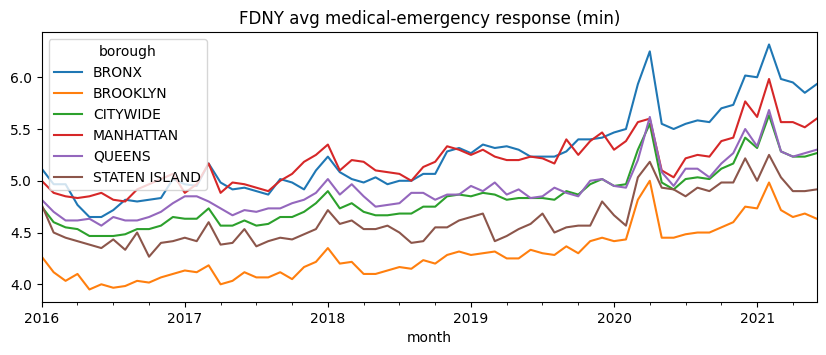

In [16]:
m = pd.read_csv(RAW / "fdny_monthly_response_times.csv", dtype=str)
m = m[m.yearmonth.str.fullmatch(r"\d{4}/\d{2}")].copy()                  # drop fiscal-year summary rows like 'FY 2021'
m["month"] = pd.to_datetime(m.yearmonth + "/01", format="%Y/%m/%d")
mm = m.averageresponsetime.str.extract(r"(?P<m>\d+):(?P<s>\d+)").astype(float)
m["avg_response_s"] = mm.m * 60 + mm.s
m["incidentcount"] = pd.to_numeric(m.incidentcount, errors="coerce")
fdny_monthly = m.rename(columns={"incidentclassification": "classification", "incidentborough": "borough"})
fdny_monthly["borough"] = fdny_monthly.borough.str.upper()
fdny_monthly = fdny_monthly[["month", "classification", "borough", "incidentcount", "avg_response_s"]].dropna(subset=["avg_response_s"])
fdny_monthly.to_csv(INTERIM / "fdny_monthly.csv", index=False)
(fdny_monthly[(fdny_monthly.classification == "Medical Emergencies") & (fdny_monthly.month >= "2016-01-01")]
   .pivot(index="month", columns="borough", values="avg_response_s") / 60).plot(figsize=(10, 3.5), title="FDNY avg medical-emergency response (min)");

## 10. Health and equity context: asthma, health survey, Census
These are the health datasets we combine with the EMS data. Asthma rates are neighbourhood (NTA) level, so they are aggregated to **borough**
(there is no NTA -> zone crosswalk yet). The survey is citywide only. Census (population, income, vehicles, poverty) joins at zone level when a key is available.

In [17]:
a = pd.read_csv(DATA / "NYC_asthma_nta_rates_2017_2019.csv")
a.columns = ["period", "geo_type", "geo_desc", "geo_id", "geo_rank", "boro_id", "borough", "nta", "area", "avg_annual_n", "rate_per_10k", "age_adj_rate_per_10k"]
for c in ["avg_annual_n", "rate_per_10k", "age_adj_rate_per_10k"]:
    a[c] = pd.to_numeric(a[c], errors="coerce")
nta = a[a.geo_type == "NTA"].dropna(subset=["rate_per_10k", "avg_annual_n"]).copy()
nta["borough"] = nta.borough.str.upper()
nta[["borough", "nta", "avg_annual_n", "rate_per_10k", "age_adj_rate_per_10k"]].to_csv(INTERIM / "asthma_nta.csv", index=False)
asthma_borough = (nta.groupby("borough").apply(lambda g: pd.Series({"asthma_visits_per_year": g.avg_annual_n.sum(),
                  "asthma_rate_per_10k": np.average(g.rate_per_10k, weights=g.avg_annual_n)}), include_groups=False).reset_index())
asthma_borough.to_csv(INTERIM / "asthma_borough.csv", index=False)
print(asthma_borough.round(1).to_string(index=False))

s = pd.read_csv(DATA / "NYC_community_health_survey.csv").rename(columns={"Prevelance": "row"})
s = s[s.row.str.startswith("Prevalence")].drop(columns="row")           # drop the confidence-interval rows
s["Year"] = s.Year.astype(int)
for c in s.columns[1:]:
    s[c] = pd.to_numeric(s[c], errors="coerce")
s.columns = [c.lower().replace(" ", "_").replace(",", "").replace("(", "").replace(")", "").replace("+", "plus") for c in s.columns]
s.to_csv(INTERIM / "health_survey_citywide.csv", index=False)
print("health survey:", s.shape)

census = None
cp = RAW / "census_acs5_2022_zcta.csv"
if cp.exists():
    c = pd.read_csv(cp, dtype={"zcta": str}).replace(-666666666, np.nan)       # Census sentinel for 'not available'
    c = c.merge(zip_to_zone, left_on="zcta", right_on="zipcode", how="inner")
    c["no_vehicle"] = c.owner_no_vehicle + c.renter_no_vehicle
    census = c.groupby("zone").agg(population=("population", "sum"), occupied_units=("occupied_housing_units", "sum"),
                                   no_vehicle=("no_vehicle", "sum"), poverty_universe=("poverty_universe", "sum"),
                                   below_poverty=("below_poverty", "sum"), median_income=("median_household_income", "median")).reset_index()
    census["pct_no_vehicle"] = census.no_vehicle / census.occupied_units
    census["pct_poverty"] = census.below_poverty / census.poverty_universe
    census = census[["zone", "population", "median_income", "pct_no_vehicle", "pct_poverty"]]
    census.to_csv(INTERIM / "census_zone.csv", index=False); print("census:", census.shape)
else:
    print("Census skipped (no key). Free key: https://api.census.gov/data/key_signup.html then CENSUS_API_KEY=<key> and rerun.")

      borough  asthma_visits_per_year  asthma_rate_per_10k
        BRONX                 15584.0                190.7
     BROOKLYN                 13317.0                115.2
    MANHATTAN                  6604.0                 89.5
       QUEENS                  7945.0                 64.1
STATEN ISLAND                  2111.0                 96.3
health survey: (11, 11)
census: (177, 5)


### Zone context table (all non-EMS, zone-level sources in one place)
One row per zone: location, population estimate, borough, health context (asthma rate), Census fields when available, and access to care
(hospitals / firehouses in the zone, distance to the nearest hospital). Borough comes from the community district containing the zone's centroid,
so this table does **not** depend on the EMS data. `HarryRowlands.ipynb` joins it onto the incident table through `zip_to_zone.csv`.

In [18]:
cd = load_geojson(RAW / "community_district_boundaries.geojson")
BORO = {"1": "MANHATTAN", "2": "BRONX", "3": "BROOKLYN", "4": "QUEENS", "5": "STATEN ISLAND"}
cd_cent = pd.DataFrame([{"boro_cd": f["props"]["boro_cd"], "lon": (c := feature_centroid(f["polys"]))[0], "lat": c[1]} for f in cd])

def borough_of(lon, lat):
    code = locate(lon, lat, cd, "boro_cd")
    if code is None:                                   # centroid fell in water / outside: nearest district centroid
        code = cd_cent.boro_cd.iloc[int(haversine_km(lon, lat, cd_cent.lon.values, cd_cent.lat.values).argmin())]
    return BORO[str(code)[0]]

zone_context = zones[["zone", "label", "lon", "lat", "pop_est"]].copy()
zone_context["borough"] = [borough_of(lo, la) for lo, la in zip(zone_context.lon, zone_context.lat)]
zone_context = zone_context.merge(asthma_borough[["borough", "asthma_rate_per_10k"]], on="borough", how="left")
if census is not None:
    zone_context = zone_context.merge(census, on="zone", how="left")

hosp_pts = posts[posts.post_type == "hospital"]
d = haversine_km(zone_context.lon.values[:, None], zone_context.lat.values[:, None], hosp_pts.lon.values[None, :], hosp_pts.lat.values[None, :])
zone_context["dist_nearest_hospital_km"] = d.min(axis=1).round(2)
n_posts = posts.groupby(["zone", "post_type"]).size().unstack(fill_value=0).rename(columns={"hospital": "n_hospitals", "firehouse": "n_firehouses"})
zone_context = zone_context.merge(n_posts, on="zone", how="left").fillna({"n_hospitals": 0, "n_firehouses": 0})

zone_context.to_csv(INTERIM / "zone_context.csv", index=False)
print(zone_context.shape, "| zones per borough:", zone_context.borough.value_counts().to_dict())
zone_context.head(3)

(178, 14) | zones per borough: {'QUEENS': 59, 'MANHATTAN': 44, 'BROOKLYN': 38, 'BRONX': 25, 'STATEN ISLAND': 12}


,zone,label,lon,lat,pop_est,borough,asthma_rate_per_10k,population,median_income,pct_no_vehicle,pct_poverty,dist_nearest_hospital_km,n_firehouses,n_hospitals
0,10001,"10001, 10118",-73.997138,40.750688,23072,MANHATTAN,89.503558,27004.0,106509.0,0.854609,0.158645,1.49,1.0,0.0
1,10002,10002,-73.986174,40.715780,74993,MANHATTAN,89.503558,76518.0,43362.0,0.827912,0.261101,0.70,2.0,1.0
2,10003,10003,-73.989159,40.731826,54682,MANHATTAN,89.503558,53877.0,152863.0,0.801817,0.121385,0.38,4.0,2.0


In [19]:
print("outputs written:")
for f in sorted(list(INTERIM.iterdir()) + [DATA / "weather_calendar_30min.csv.gz"]):
    print(" ", f.resolve().relative_to(ROOT))
print("\nNext: HarryRowlands.ipynb fetches EMS into ems_raw/ and links these tables onto it (cells after the lag features).")

outputs written:
  notebooks/data/interim/asthma_borough.csv
  notebooks/data/interim/asthma_nta.csv
  notebooks/data/interim/census_zone.csv
  notebooks/data/interim/fdny_monthly.csv
  notebooks/data/interim/health_survey_citywide.csv
  notebooks/data/interim/posts.csv
  notebooks/data/interim/zip_to_zone.csv
  notebooks/data/interim/zone_context.csv
  notebooks/data/interim/zones.csv
  notebooks/data/weather_calendar_30min.csv.gz

Next: HarryRowlands.ipynb fetches EMS into ems_raw/ and links these tables onto it (cells after the lag features).
